In [1]:
import pandas as pd

In [2]:
#pip install pandas --quiet

In [3]:
#pip install numpy 

In [2]:
import numpy as np


In [3]:
med_df = pd.read_csv('insurance_ml_dataset_1000(Sheet1).csv')

In [4]:
med_df

,age,sex,bmi,children,smoker,region,charges
0,56,male,32.08,5,no,southeast,10698.41
1,46,female,26.15,0,no,southeast,9231.74
2,32,female,21.84,2,no,southwest,7436.11
3,60,female,39.93,5,no,southwest,12720.24
4,25,male,25.65,2,yes,southeast,25733.30
...,...,...,...,...,...,...,...
995,22,male,17.77,1,no,southwest,6740.76
996,40,male,25.56,4,no,southeast,11345.19
997,27,female,16.05,3,no,northwest,5672.61
998,61,male,33.50,3,yes,southeast,23543.87


In [5]:
med_df.charges.corr(med_df.children)

np.float64(-0.06525679091449656)

In [6]:
med_df.charges.corr(med_df.age)

np.float64(0.1401016509780035)

In [9]:
med_df.charges.corr(med_df.bmi)

np.float64(0.2893308581028763)

In [7]:
smoker_val = {'no':0 , 'yes':1}
smoker_numeric = med_df.smoker.map(smoker_val)
smoker_numeric

0      0
1      0
2      0
3      0
4      1
      ..
995    0
996    0
997    0
998    1
999    0
Name: smoker, Length: 1000, dtype: int64

In [8]:
med_df.charges.corr(smoker_numeric)

np.float64(0.9373387318700586)

In [12]:
#med_df.corr()

In [9]:
med_df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.048563,0.013751,0.140102
bmi,0.048563,1.000000,0.021941,0.289331
children,0.013751,0.021941,1.000000,-0.065257
charges,0.140102,0.289331,-0.065257,1.000000


In [10]:
non_smoker_df = med_df[med_df.smoker== 'no']

In [15]:
#pip install matplotlib seaborn --quiet

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns


<Axes: title={'center': 'Age vs. Charges'}, xlabel='bmi', ylabel='charges'>

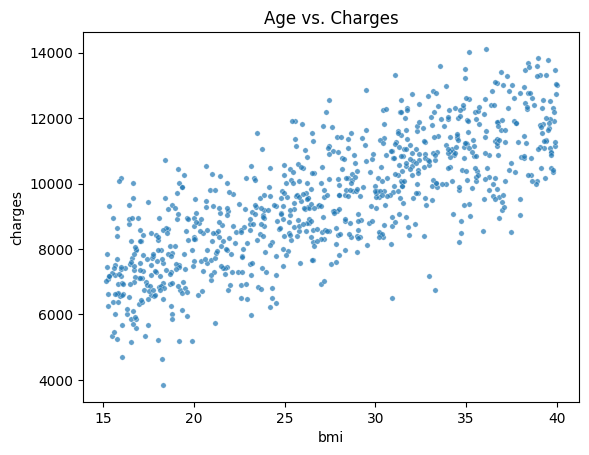

In [17]:
plt.title('Age vs. Charges')
sns.scatterplot(data = non_smoker_df, x = 'bmi', y = 'charges', alpha = 0.7, s =15)

In [18]:
def estimated_charge(bmi , w, b):
    return w*bmi + b

In [19]:
w = 50
b = 100

In [20]:
bmi = non_smoker_df.bmi
estimate_charge = estimated_charge(bmi, w, b)

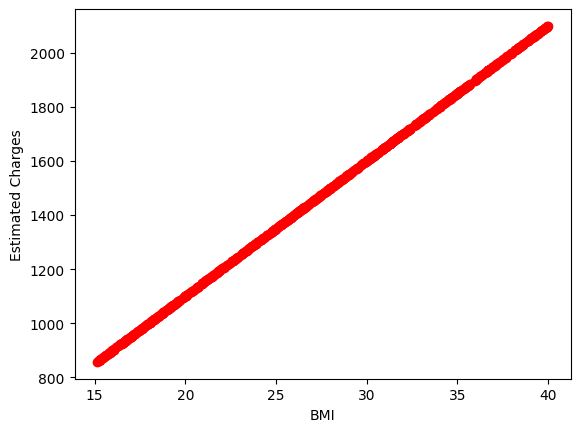

In [21]:
plt.plot(bmi, estimate_charge, 'r-o');
plt.xlabel('BMI');
plt.ylabel('Estimated Charges');

In [22]:
def try_parameters(w, b):
    bmis = non_smoker_df.bmi
    target = non_smoker_df.charges

    estimate_charges = estimated_charge(bmis, w, b)

    plt.plot(bmis, estimate_charges, 'r', alpha =0.9);
    plt.scatter(bmis, target, s=8, alpha = 0.8);
    plt.xlabel('BMI');
    plt.ylabel('Charges');
    plt.legend(['Estimate', 'Actual']);

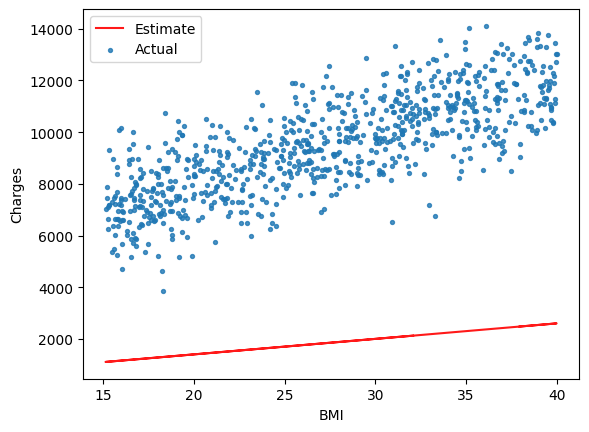

In [23]:
try_parameters(60, 200)

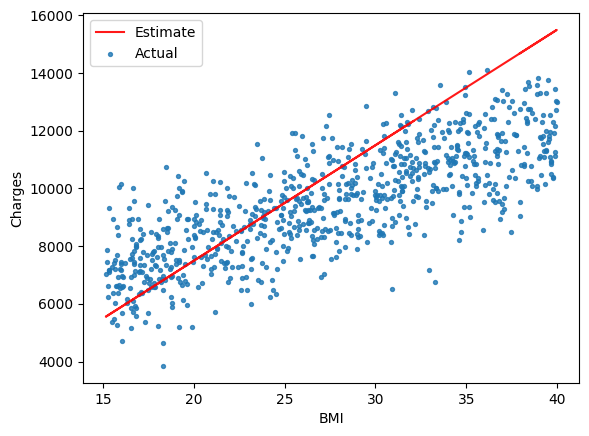

In [24]:
try_parameters(400, -500)

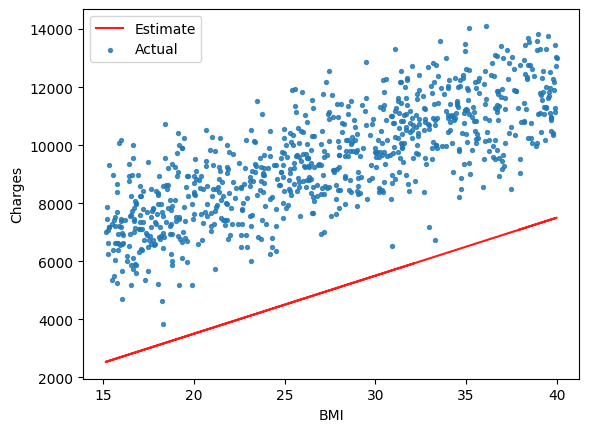

In [25]:
try_parameters(200, -500)

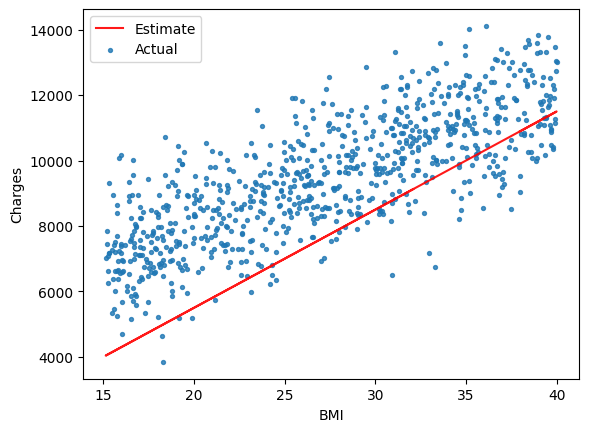

In [26]:
try_parameters(300, -500)

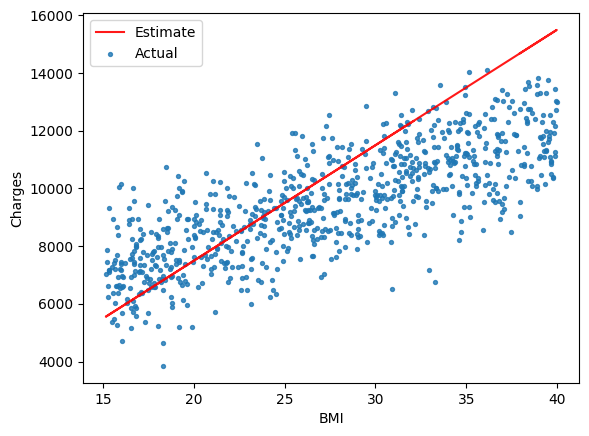

In [27]:
try_parameters(400, -500)

In [28]:
targets = non_smoker_df.charges
targets

0      10698.41
1       9231.74
2       7436.11
3      12720.24
5       9542.15
         ...   
994    11990.00
995     6740.76
996    11345.19
997     5672.61
999     9033.87
Name: charges, Length: 823, dtype: float64

In [29]:
predictions = estimate_charge
predictions

0      1704.0
1      1407.5
2      1192.0
3      2096.5
5      1414.0
        ...  
994    2071.0
995     988.5
996    1378.0
997     902.5
999    1997.5
Name: bmi, Length: 823, dtype: float64

In [30]:
def rmse(targets, predictions):
    return np.sqrt(np.mean(np.square(targets- predictions)))

In [31]:
w = 50
b = 100

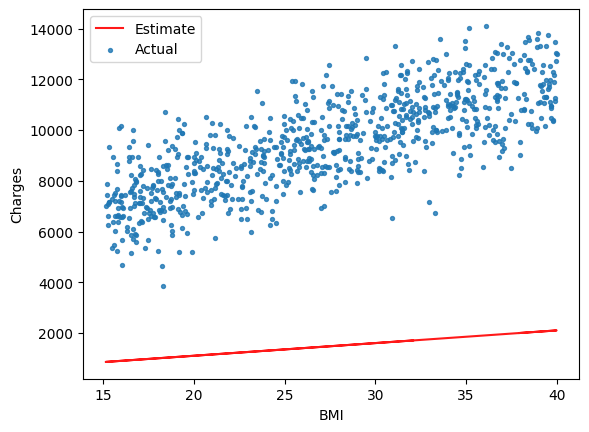

In [32]:
try_parameters(w, b)

In [33]:
targets = non_smoker_df['charges']
predicted = estimated_charge(non_smoker_df.bmi , w, b)

In [34]:
rmse(targets, predicted)

np.float64(8185.375489434925)

In [35]:
def try_parameters(w, b):
    bmis = non_smoker_df.bmi
    target = non_smoker_df.charges
    predictions = estimated_charge(bmis, w, b)

    plt.plot(bmis, predictions, 'r', alpha = 0.9);
    plt.scatter(bmis, target, s=8, alpha = 0.8);
    plt.xlabel('BMI');
    plt.ylabel('Charges');
    plt.legend(['Predictions','Actual']);

    loss = rmse(target, predictions)
    print("RMSE Loss : ", loss)

RMSE Loss :  8185.375489434925


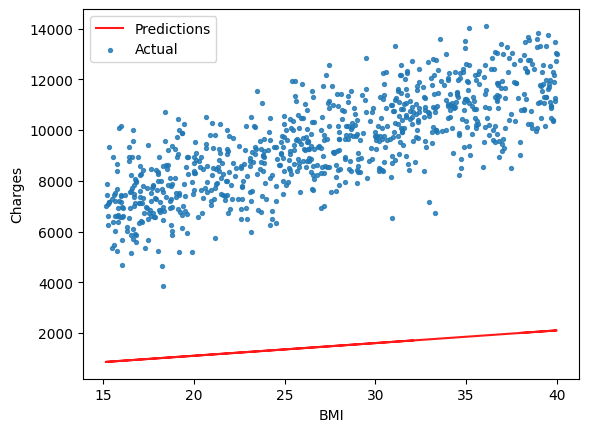

In [36]:
try_parameters(50, 100)

RMSE Loss :  2844.0779369166194


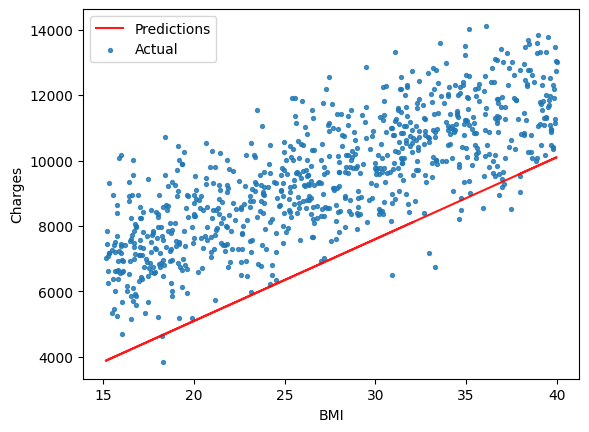

In [37]:
try_parameters(250, 100)

RMSE Loss :  1614.415876686126


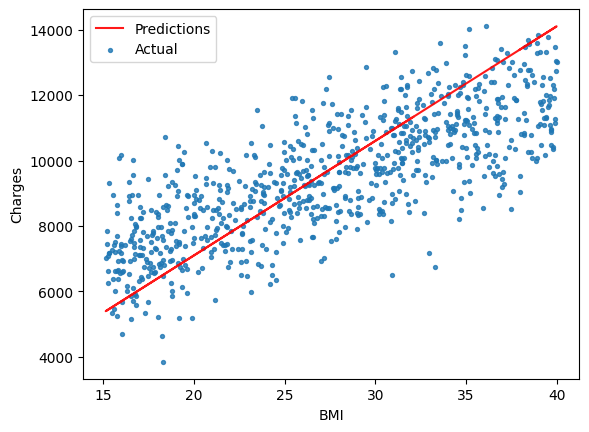

In [38]:
try_parameters(350, 100)

# Linear Regression using scikit-learn

In [39]:
#!pip install scikit-learn --quiet

In [40]:
from sklearn.linear_model import LinearRegression

In [41]:
model = LinearRegression()

In [42]:
help(model.fit)

Help on method fit in module sklearn.linear_model._base:

fit(X, y, sample_weight=None) method of sklearn.linear_model._base.LinearRegression instance
    Fit linear model.
    
    Parameters
    ----------
    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        Training data.
    
    y : array-like of shape (n_samples,) or (n_samples, n_targets)
        Target values. Will be cast to X's dtype if necessary.
    
    sample_weight : array-like of shape (n_samples,), default=None
        Individual weights for each sample.
    
        .. versionadded:: 0.17
           parameter *sample_weight* support to LinearRegression.
    
    Returns
    -------
    self : object
        Fitted Estimator.



In [45]:
inputs = non_smoker_df[['bmi']]
targets = non_smoker_df.charges

In [46]:
print('inputs.shape :', inputs.shape)
print('targets.shape :', targets.shape)

inputs.shape : (823, 1)
targets.shape : (823,)


In [48]:
type(inputs)


pandas.DataFrame

In [49]:
type(targets)

pandas.Series

In [50]:
model.fit(inputs, targets)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [51]:
model.predict(np.array([[23],
                       [26],
                       [30]]))

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([ 8613.0773992 ,  9219.89508293, 10028.9853279 ])

In [52]:
predictions = model.predict(inputs)

In [53]:
predictions

array([10449.71225528,  9250.23596712,  8378.44122816, 12037.55186104,
        9276.53140008,  7822.19168474, 11014.05270115, 10502.30312121,
        8111.44144732,  7411.57838542, 10435.553176  , 10304.07601119,
       11802.91568999,  7759.48719076,  9181.46329629, 11766.50662897,
        9116.7360767 , 10223.16698669,  9005.48616801,  8382.48667939,
       11970.80191583,  9064.14521077, 11515.68865303,  8157.96413641,
        7152.66950703, 10289.9169319 ,  8857.82719831, 11366.00695771,
        9387.78130876,  7933.44159343, 10921.00732298, 10892.6891644 ,
       11266.8934027 , 10844.14374971, 10162.48521832,  7658.35091014,
       11651.21126906, 10113.93980362, 11022.1436036 ,  9430.25854662,
        7587.5555137 ,  7628.01002595,  9171.34966823,  8008.28244109,
        9480.82668693,  7320.55573286,  8354.16852081, 11028.21178044,
        7053.55595202,  7361.01024511,  8979.19073505,  9422.16764417,
       10028.9853279 ,  8469.46388072, 10508.37129804, 11343.75697597,
      

In [55]:
targets

0      10698.41
1       9231.74
2       7436.11
3      12720.24
5       9542.15
         ...   
994    11990.00
995     6740.76
996    11345.19
997     5672.61
999     9033.87
Name: charges, Length: 823, dtype: float64

In [56]:
rmse(targets, predictions)

np.float64(1197.4245067041963)

In [57]:
# W
model.coef_

array([202.27256124])

In [59]:
# b
model.intercept_

np.float64(3960.8084906278445)

RMSE Loss :  1197.4245067041963


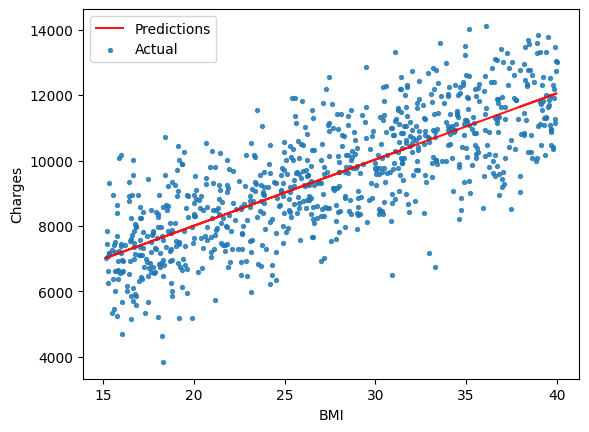

In [60]:
try_parameters(model.coef_, model.intercept_)

# SGDRegressor


In [61]:
from sklearn.linear_model import SGDRegressor

In [62]:
model2 = SGDRegressor()

In [63]:
help(model2.fit)

Help on method fit in module sklearn.linear_model._stochastic_gradient:

fit(X, y, coef_init=None, intercept_init=None, sample_weight=None) method of sklearn.linear_model._stochastic_gradient.SGDRegressor instance
    Fit linear model with Stochastic Gradient Descent.
    
    Parameters
    ----------
    X : {array-like, sparse matrix}, shape (n_samples, n_features)
        Training data.
    
    y : ndarray of shape (n_samples,)
        Target values.
    
    coef_init : ndarray of shape (n_features,), default=None
        The initial coefficients to warm-start the optimization.
    
    intercept_init : ndarray of shape (1,), default=None
        The initial intercept to warm-start the optimization.
    
    sample_weight : array-like, shape (n_samples,), default=None
        Weights applied to individual samples (1. for unweighted).
    
    Returns
    -------
    self : object
        Fitted `SGDRegressor` estimator.



In [64]:
print('inputs.shape :', inputs.shape)
print('targets.shape :', targets.shape)

inputs.shape : (823, 1)
targets.shape : (823,)


In [65]:
model2.fit(inputs, targets)

,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide `.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None


In [66]:
model2.predict(np.array([[23],
                       [26],
                       [30]]))

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but SGDRegressor was fitted with feature names
  warnings.warn(


array([ 8553.47927149,  9249.14481894, 10176.69888219])

In [67]:
model.predict(np.array([[23],
                       [26],
                       [30]]))

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([ 8613.0773992 ,  9219.89508293, 10028.9853279 ])

In [68]:
predictions2 = model2.predict(inputs)
predictions2

array([10659.02699509,  9283.92809631,  8284.48859315, 12479.35184424,
        9314.07360336,  7646.79517465, 11305.99595421, 10719.3180092 ,
        7978.39575227,  7176.06148755, 10642.79479898, 10492.0672637 ,
       12210.36116589,  7574.90973475,  9205.08600093, 12168.62123304,
        9130.88167587, 10399.31185738,  9003.34299217,  8289.12636346,
       12402.82863402,  9070.59066176, 11881.07947343,  8031.73011091,
        6879.24418731, 10475.8350676 ,  8834.06437563, 11709.48197173,
        9441.61228706,  7774.33385835, 11199.32723694, 11166.86284472,
       11595.85659898, 11111.20960093, 10329.74530263,  7458.96547684,
       12036.44477903, 10274.09205884, 11315.27149485,  9490.30887538,
        7377.80449631,  7424.18219947,  9193.49157514,  7860.1326092 ,
        9548.28100434,  7071.71165543,  8256.66197125, 11322.22815032,
        6765.61881456,  7118.0893586 ,  8973.19748512,  9481.03333475,
       10176.69888219,  8388.83842526, 10726.27466468, 11683.97423499,
      

In [69]:
predictions

array([10449.71225528,  9250.23596712,  8378.44122816, 12037.55186104,
        9276.53140008,  7822.19168474, 11014.05270115, 10502.30312121,
        8111.44144732,  7411.57838542, 10435.553176  , 10304.07601119,
       11802.91568999,  7759.48719076,  9181.46329629, 11766.50662897,
        9116.7360767 , 10223.16698669,  9005.48616801,  8382.48667939,
       11970.80191583,  9064.14521077, 11515.68865303,  8157.96413641,
        7152.66950703, 10289.9169319 ,  8857.82719831, 11366.00695771,
        9387.78130876,  7933.44159343, 10921.00732298, 10892.6891644 ,
       11266.8934027 , 10844.14374971, 10162.48521832,  7658.35091014,
       11651.21126906, 10113.93980362, 11022.1436036 ,  9430.25854662,
        7587.5555137 ,  7628.01002595,  9171.34966823,  8008.28244109,
        9480.82668693,  7320.55573286,  8354.16852081, 11028.21178044,
        7053.55595202,  7361.01024511,  8979.19073505,  9422.16764417,
       10028.9853279 ,  8469.46388072, 10508.37129804, 11343.75697597,
      

In [70]:
targets

0      10698.41
1       9231.74
2       7436.11
3      12720.24
5       9542.15
         ...   
994    11990.00
995     6740.76
996    11345.19
997     5672.61
999     9033.87
Name: charges, Length: 823, dtype: float64

In [72]:
rmse(predictions2, targets)

np.float64(1218.3610725582596)

In [73]:
#w
model2.coef_

array([231.88851581])

In [74]:
#b
model2.intercept_

array([3220.04340775])

RMSE Loss :  1218.3610725582596


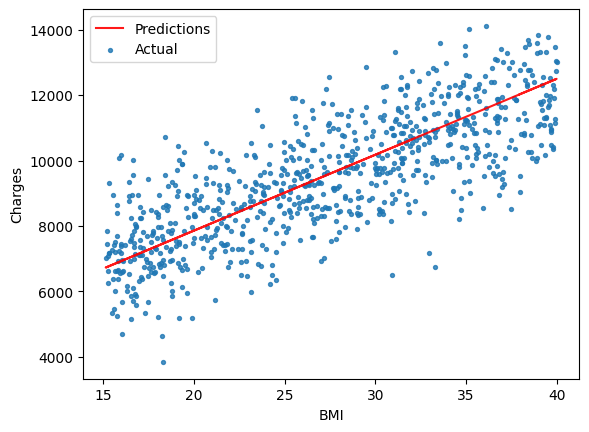

In [75]:
try_parameters(model2.coef_, model2.intercept_)

RMSE Loss :  1197.4245067041963


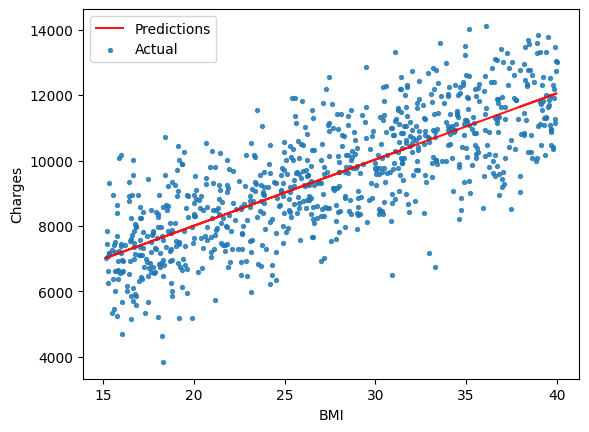

In [76]:
try_parameters(model.coef_, model.intercept_)

In [77]:
smoker_df = med_df[med_df.smoker == 'yes']

In [78]:
smoker_df

,age,sex,bmi,children,smoker,region,charges
4,25,male,25.65,2,yes,southeast,25733.30
13,57,female,21.83,0,yes,northeast,19649.19
26,39,female,20.33,5,yes,northeast,23239.98
32,33,male,39.20,2,yes,southwest,31202.59
34,64,female,36.72,2,yes,southwest,30118.54
...,...,...,...,...,...,...,...
974,43,female,22.63,5,yes,southeast,19486.61
975,21,female,20.32,2,yes,southwest,18100.56
981,64,male,34.15,0,yes,northeast,26356.43
983,43,female,31.62,4,yes,northwest,28068.63


In [79]:
input2 = smoker_df[['bmi']]

In [80]:
target2 = smoker_df.charges

In [82]:
input2.shape

(177, 1)

In [84]:
type(target2)

pandas.Series

In [85]:
model3 = LinearRegression()

In [86]:
model3.fit(input2, target2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [87]:
model3.coef_

array([211.17124078])

In [88]:
model3.intercept_

np.float64(19166.924272059805)

In [89]:
model3.predict(np.array([[23],
                        [27],
                        [30]]))

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([24023.86281001, 24868.54777313, 25502.06149547])

In [91]:
predictions3 = model3.predict(input2)
predictions3

array([24583.46659808, 23776.79245829, 23460.03559712, 27444.83691065,
       26921.13223351, 22505.5415888 , 25953.96795074, 25407.03443712,
       23973.18171222, 24737.62160384, 24870.65948554, 26042.65987187,
       25067.04873946, 26560.02941178, 25694.22732458, 27278.01163043,
       22609.01549678, 25191.63977152, 26931.69079555, 26103.89953169,
       26636.05105846, 22756.83536533, 27058.39354002, 24722.83961699,
       25732.23814792, 24112.55473114, 26503.01317677, 26131.35179299,
       23694.43567439, 24651.04139512, 25461.93895972, 27151.30888596,
       23447.36532268, 25668.88677569, 23288.98689209, 23639.53115179,
       23198.18325856, 27455.39547269, 22723.0479668 , 26709.96099273,
       26065.88870835, 26790.20606423, 25423.92813638, 23422.02477378,
       25138.84696133, 27430.05492379, 22359.83343266, 27360.36841434,
       24915.0054461 , 23960.51143777, 26921.13223351, 27493.40629603,
       26931.69079555, 25328.90107803, 26232.71398857, 24338.50795877,
      

In [92]:
target2

4      25733.30
13     19649.19
26     23239.98
32     31202.59
34     30118.54
         ...   
974    19486.61
975    18100.56
981    26356.43
983    28068.63
998    23543.87
Name: charges, Length: 177, dtype: float64

In [93]:
rmse(predictions3, target2)

np.float64(3042.803610419353)

RMSE Loss :  15495.765403726471


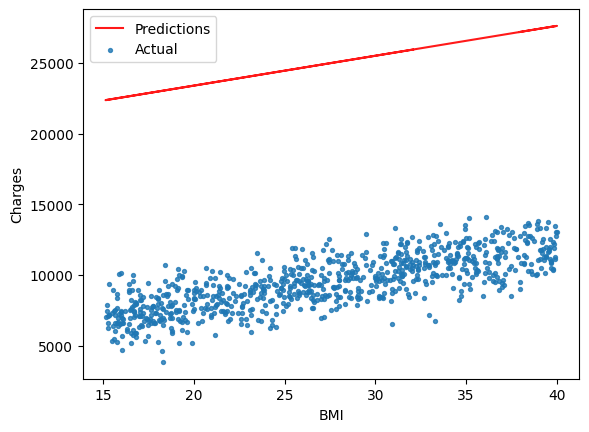

In [94]:
try_parameters(model3.coef_, model3.intercept_)